# Thực hành 4 — Tự cài Naive Bayes và làm trơn Laplace
Theo mục 5.3: kho sáu tin nhắn, điểm bằng tích xác suất, so sánh alpha bằng 0 và 1.

Chọn **Run All** để chạy độc lập notebook này. Trên Colab, tải CSV cần dùng vào Files hoặc thư mục `data/`.


In [1]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


## Mã và kết quả

In [2]:
from collections import Counter

kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]
tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Tu dien co {V} tu:")
for i in range(0, V, 9):
    print("  " + " ".join(tu_dien[i:i + 9]))
print()

dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
    for t in cau.split():
        dem[nhan][t] += 1
        tong[nhan] += 1

print("So lan xuat hien cua tung tu")
print(f"  {'tu':12s} {'rac':>5s} {'thuong':>7s}")
for t in tu_dien:
    print(f"  {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()

def xac_suat(tu, nhan, alpha):
    """P(từ | nhãn) có làm trơn Laplace với hệ số alpha."""
    return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)

def diem(cau, nhan, alpha):
    """Tích của xác suất tiên nghiệm và các xác suất từ."""
    p = 0.5  # Hai lớp cân bằng nên tiên nghiệm bằng nhau.
    for t in cau.split():
        if t in tu_dien:
            p *= xac_suat(t, nhan, alpha)
    return p

cau_thu = "trung thuong bai tap"
print(f'Tin nhan thu: "{cau_thu}"')
print("Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.")
print()
for alpha in [0.0, 1.0]:
    d_rac = diem(cau_thu, 1, alpha)
    d_thuong = diem(cau_thu, 0, alpha)
    ket = "rac" if d_rac > d_thuong else "thuong"
    print(f"alpha = {alpha}")
    print(f"  diem lop rac    = {d_rac:.10f}")
    print(f"  diem lop thuong = {d_thuong:.10f}")
    print(f"  ket luan        = {ket}")
    print()
print("Khong lam tron, CA HAI diem deu bang 0 nen mo hinh te liet.")
print("Lop rac bang 0 vi tu 'bai' chua tung xuat hien o lop rac.")
print("Lop thuong bang 0 vi tu 'trung' chua tung xuat hien o lop thuong.")
print("Co lam tron, diem lop rac lon hon va mo hinh ket luan dung.")

Tu dien co 18 tu:
  bai chieu click gia giam gui hop khuyen lieu
  mai ngay nhom nop tai tap thay thuong trung

So lan xuat hien cua tung tu
  tu             rac  thuong
  bai              0       1
  chieu            0       1
  click            1       0
  gia              1       0
  giam             1       0
  gui              0       1
  hop              0       1
  khuyen           1       0
  lieu             0       1
  mai              1       2
  ngay             1       0
  nhom             0       2
  nop              0       1
  tai              0       1
  tap              0       1
  thay             0       1
  thuong           2       0
  trung            2       0

Tin nhan thu: "trung thuong bai tap"
Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.

alpha = 0.0
  diem lop rac    = 0.0000000000
  diem lop thuong = 0.0000000000
  ket luan        = thuong

alpha = 1.0
  diem lop rac    = 0.0000073212
  diem lop thuong = 0.0000021656
  ket luan        = rac


## Hình minh họa bổ sung
Phần vẽ dưới đây bổ sung cho mã mẫu; hình được lưu vào `figures/` trước khi hiển thị.

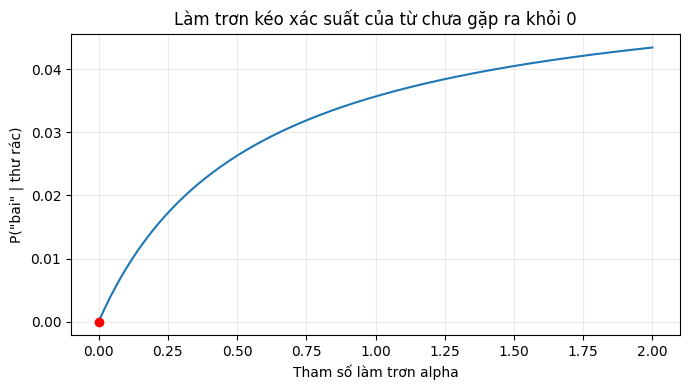

In [3]:
import numpy as np
import matplotlib.pyplot as plt

cac_alpha = np.linspace(0, 2, 201)
plt.figure(figsize=(7, 4))
plt.plot(cac_alpha, [xac_suat("bai", 1, a) for a in cac_alpha])
plt.scatter([0], [0], color="red", zorder=3)
plt.title("Làm trơn kéo xác suất của từ chưa gặp ra khỏi 0")
plt.xlabel("Tham số làm trơn alpha")
plt.ylabel('P("bai" | thư rác)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "d4_lam_tron_laplace.png", dpi=150)
plt.show()